# Challenge 01 — VQE: Ground-State Energy of the H₂ Molecule
**Qiskit Fall Fest 2026 · Team Cdevi Code · Intermediate**

## Goal
Find the **lowest possible energy** (the *ground-state energy*) of a hydrogen molecule, H₂, using the
**Variational Quantum Eigensolver (VQE)**, and prove the answer is right by comparing it with an
exact classical calculation.

## Why does this matter?
The ground-state energy of a molecule decides its shape, how strongly its atoms are bound and how it
reacts. Computing it exactly on a classical computer gets exponentially expensive as molecules grow.
Quantum computers may handle this better because a register of qubits can naturally represent the
quantum state of electrons.

## Roadmap of this notebook
| Phase | What we do | Output |
|---|---|---|
| **1** | Define H₂ in PySCF → build its Hamiltonian → map to qubits → **exact classical answer** | the reference energy |
| 2 | Build the ansatz (parameterised quantum circuit) | a circuit with tunable angles |
| 3 | Run VQE (quantum circuit + classical optimizer) | VQE energy |
| 4 | Compare VQE vs exact, analyse error, discuss | verification and plots |

> **Units:** energies are in **Hartree (Ha)**, the natural unit of quantum chemistry
> (1 Ha ≈ 27.211 eV ≈ 627.5 kcal/mol). *Chemical accuracy* is a target error of
> **1.6 mHa** (= 1 kcal/mol); below it, a computed energy is accurate enough to predict chemistry.

## 0. Setup: imports and versions
Qiskit's API changes between releases, so we **print every library version**. Anyone re-running this
notebook can then check they have the same environment (see `requirements.txt`).

| Library | Role in this notebook |
|---|---|
| `pyscf` | Classical quantum-chemistry engine: computes the integrals that define the H₂ Hamiltonian |
| `qiskit_nature` | Bridges chemistry and Qiskit: turns PySCF output into a fermionic Hamiltonian and maps it onto qubits |
| `qiskit` | Core quantum-circuit and operator library (`SparsePauliOp`) |
| `qiskit_algorithms` | Ready-made algorithms: `NumPyMinimumEigensolver` (exact) and later `VQE` |
| `numpy` | Linear algebra for our independent cross-check |

In [1]:
import numpy as np

import pyscf
import qiskit
import qiskit_nature
import qiskit_algorithms

# Chemistry -> Qiskit bridge
from qiskit_nature.units import DistanceUnit                         # lets us say "Angstrom" explicitly
from qiskit_nature.second_q.drivers import PySCFDriver               # runs PySCF for us
from qiskit_nature.second_q.mappers import JordanWignerMapper        # fermions -> qubits
from qiskit_nature.second_q.algorithms import GroundStateEigensolver # chemistry-aware solver wrapper

# Exact (classical) eigensolver used as our ground truth
from qiskit_algorithms import NumPyMinimumEigensolver

# Independent cross-check with PySCF's own Full Configuration Interaction (FCI) solver
from pyscf import gto, scf, fci

print(f"qiskit            {qiskit.__version__}")
print(f"qiskit-nature     {qiskit_nature.__version__}")
print(f"qiskit-algorithms {qiskit_algorithms.__version__}")
print(f"pyscf             {pyscf.__version__}")
print(f"numpy             {np.__version__}")

qiskit            2.2.3
qiskit-nature     0.8.0
qiskit-algorithms 0.4.0
pyscf             2.15.0
numpy             2.2.6


## 1. Define the H₂ molecule with PySCF

To describe a molecule we must choose four things:

1. **Geometry**: where the nuclei sit. H₂ has two hydrogen nuclei on the z-axis, **0.735 Å** apart.
   That is close to H₂'s experimental equilibrium bond length (≈ 0.741 Å), the distance where the
   molecule is most stable.
2. **Charge = 0**: a neutral molecule, so 2 protons and **2 electrons**.
3. **Spin = 0**: PySCF's `spin` is 2S, the number of unpaired electrons. Both electrons are paired
   (one spin-up ↑, one spin-down ↓), which is the *singlet* ground state.
4. **Basis set = STO-3G**: electrons live in *orbitals*, and a basis set is the menu of mathematical
   functions used to build them. STO-3G is the smallest standard basis: **one 1s function per H atom**.
   Two atoms give 2 *spatial orbitals*, which combine into
   - a **bonding** orbital σg (lower energy, electrons pulled between the nuclei), and
   - an **antibonding** orbital σu* (higher energy).

**Behind the scenes, the `PySCFDriver`:**
- runs a **Hartree–Fock (HF)** calculation, a mean-field approximation in which each electron feels
  only the *average* repulsion of the others;
- uses the HF molecular orbitals to compute the **one- and two-electron integrals**. These numbers are
  exactly what the Hamiltonian needs.

HF misses *electron correlation* (electrons actively avoiding each other). The gap between the HF
energy and the exact energy is the **correlation energy**, and recovering it is the whole point of VQE.

In [2]:
# --- Molecule specification -------------------------------------------------
BOND_LENGTH = 0.735  # Angstrom, close to the H2 equilibrium bond length

driver = PySCFDriver(
    atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}",  # "element x y z; element x y z"
    basis="sto3g",                          # minimal basis: one 1s orbital per H atom
    charge=0,                               # neutral molecule -> 2 electrons
    spin=0,                                 # 2S = 0 -> all electrons paired (singlet)
    unit=DistanceUnit.ANGSTROM,             # coordinates above are in Angstrom
)

# driver.run() calls PySCF (Hartree-Fock + integrals) and packages everything
# into an ElectronicStructureProblem object.
problem = driver.run()

n_spatial = problem.num_spatial_orbitals   # number of molecular orbitals
n_alpha, n_beta = problem.num_particles    # (# spin-up electrons, # spin-down electrons)
nuclear_repulsion = problem.hamiltonian.nuclear_repulsion_energy
hf_energy = problem.reference_energy       # Hartree-Fock total energy

print(f"Spatial orbitals          : {n_spatial}")
print(f"Spin orbitals (= qubits)  : {2 * n_spatial}")
print(f"Electrons (alpha, beta)   : ({n_alpha}, {n_beta})")
print(f"Nuclear repulsion energy  : {nuclear_repulsion:.6f} Ha")
print(f"Hartree-Fock total energy : {hf_energy:.6f} Ha")

Spatial orbitals          : 2
Spin orbitals (= qubits)  : 4
Electrons (alpha, beta)   : (1, 1)
Nuclear repulsion energy  : 0.719969 Ha
Hartree-Fock total energy : -1.116999 Ha


**Reading the output**
- **2 spatial orbitals × 2 spin directions = 4 spin orbitals**, and each spin orbital will become one qubit.
- **Nuclear repulsion** is the classical Coulomb repulsion between the two protons. The nuclei are
  treated as fixed (the *Born–Oppenheimer approximation*), so this term is just a constant that we
  add back at the end.
- The **Hartree–Fock energy** is our starting point. The true answer must be *lower* (variational principle).

## 2. The electronic Hamiltonian (second quantisation)

The **Hamiltonian** $\hat H$ is the operator for the total energy, and its lowest eigenvalue is the
ground-state energy. In *second quantisation* it is written with operators that **create** ($a_p^\dagger$)
or **destroy** ($a_q$) an electron in spin orbital $p$ or $q$:

$$
\hat H_{\text{el}} \;=\; \sum_{pq} h_{pq}\, a_p^\dagger a_q
\;+\; \tfrac12 \sum_{pqrs} h_{pqrs}\, a_p^\dagger a_q^\dagger a_r a_s
$$

- $h_{pq}$ are **one-electron integrals**: kinetic energy plus attraction to the nuclei.
- $h_{pqrs}$ are **two-electron integrals**: electron–electron repulsion.
- PySCF computed all of these numbers in the previous cell.

The full molecular energy is $E_{\text{total}} = E_{\text{electronic}} + E_{\text{nuclear repulsion}}$.

In [3]:
# The fermionic (electron) Hamiltonian as a sum of creation/annihilation terms.
fermionic_op = problem.hamiltonian.second_q_op()

print(f"Number of fermionic terms: {len(fermionic_op)}")
print("First few terms (operator label -> coefficient in Ha):")
# '+_p' means a_p^dagger (create in spin-orbital p), '-_q' means a_q (destroy in q)
for label, coeff in list(fermionic_op.items())[:6]:
    print(f"  {label:<24} {coeff.real:+.6f}")

Number of fermionic terms: 36
First few terms (operator label -> coefficient in Ha):
  +_0 +_0 -_0 -_0          +0.337855
  +_0 +_1 -_1 -_0          +0.332291
  +_0 +_2 -_2 -_0          +0.337855
  +_0 +_3 -_3 -_0          +0.332291
  +_0 +_0 -_1 -_1          +0.090466
  +_0 +_1 -_0 -_1          +0.090466


## 3. Fermion → qubit mapping (Jordan–Wigner)

Quantum computers apply **Pauli operators** ($I, X, Y, Z$) to qubits, not fermionic operators, so the
Hamiltonian has to be translated.

**The Jordan–Wigner (JW) mapping** is the most direct translation:
- **One qubit per spin orbital.** $|1\rangle$ = orbital occupied, $|0\rangle$ = empty.
- Electrons are **fermions**: swapping two of them flips the sign of the wavefunction (the root of the
  Pauli exclusion principle). JW keeps track of that sign with a *string of Z operators*:

$$
a_j^\dagger \;=\; \Big(\prod_{k<j} Z_k\Big)\,\frac{X_j - iY_j}{2}
$$

After mapping, $\hat H$ becomes a weighted sum of Pauli strings,
$\hat H = \sum_i c_i P_i$. A quantum computer can measure each $P_i$ directly.

**Qubit layout (Qiskit Nature convention):** qubits 0–1 hold the **spin-up (α)** orbitals σg and σu*,
and qubits 2–3 hold the **spin-down (β)** orbitals. Qiskit prints Pauli strings
**right-to-left**, so the rightmost character acts on qubit 0.

*Why JW?* It is the simplest mapping to explain and verify. Alternatives such as the Parity or
Bravyi–Kitaev mappings can save qubits or shorten Z-strings; we may compare them later.

In [4]:
mapper = JordanWignerMapper()

# Translate the fermionic Hamiltonian into a qubit Hamiltonian (a SparsePauliOp).
qubit_op = mapper.map(fermionic_op)

print(f"Qubits needed        : {qubit_op.num_qubits}")
print(f"Number of Pauli terms: {len(qubit_op)}\n")
print(f"{'Pauli string':>12}   coefficient (Ha)")
# Every coefficient must be real because the Hamiltonian is Hermitian (energies are real numbers).
for pauli, coeff in sorted(zip(qubit_op.paulis.to_labels(), qubit_op.coeffs), key=lambda t: -abs(t[1])):
    print(f"{pauli:>12}   {coeff.real:+.6f}")

assert np.allclose(qubit_op.coeffs.imag, 0), "Hamiltonian coefficients should be real"
print(f"\nHamiltonian is Hermitian: {np.allclose(qubit_op.to_matrix(), qubit_op.to_matrix().conj().T)}")

Qubits needed        : 4
Number of Pauli terms: 15

Pauli string   coefficient (Ha)
        IIII   -0.810548
        IIZI   -0.225753
        ZIII   -0.225753
        ZIZI   +0.174643
        IZII   +0.172184
        IIIZ   +0.172184
        IZIZ   +0.168928
        ZIIZ   +0.166145
        IZZI   +0.166145
        IIZZ   +0.120913
        ZZII   +0.120913
        YYYY   +0.045233
        XXYY   +0.045233
        YYXX   +0.045233
        XXXX   +0.045233

Hamiltonian is Hermitian: True


**Reading the output**
- **15 Pauli terms on 4 qubits.** `IIII` is a constant energy shift.
- Terms built only from **I and Z** are *diagonal*: they just count which orbitals are occupied
  (orbital energies plus Coulomb repulsion between occupied orbitals).
- The **XXYY / YYXX / XXXX / YYYY** terms are the interesting ones. They move **both electrons
  together** from the bonding to the antibonding orbital. This *double excitation* is exactly the
  electron correlation that Hartree–Fock misses, and the reason VQE can beat HF.

## 4. Exact classical baseline (our "answer key")

Before trusting a quantum algorithm we need the **right answer**. H₂ in STO-3G needs only 4 qubits, so
the Hamiltonian is a 2⁴ × 2⁴ = **16 × 16 matrix**, small enough to **diagonalise exactly** on a laptop.

We compute the exact ground-state energy **three independent ways**. If all three agree, we can trust
the reference completely:

| Method | What it does |
|---|---|
| **A. `NumPyMinimumEigensolver`** (Qiskit) | Exact diagonalisation of the qubit Hamiltonian. `GroundStateEigensolver` adds the nuclear repulsion for us. |
| **B. `numpy.linalg.eigvalsh`** | We build the 16×16 matrix ourselves and take its smallest eigenvalue. Checks the Qiskit tooling. |
| **C. PySCF FCI** | *Full Configuration Interaction*: exact answer computed directly from chemistry, with **no qubit mapping**. Checks the mapping itself. |

> **Caveat (honest scaling note):** exact diagonalisation costs grow as 2^(qubits). It is trivial here
> but impossible for large molecules. That cost is the motivation for VQE.

In [5]:
# --- Method A: Qiskit's exact eigensolver -----------------------------------
exact_solver = GroundStateEigensolver(mapper, NumPyMinimumEigensolver())
exact_result = exact_solver.solve(problem)

E_electronic_exact = exact_result.groundenergy          # electronic part only
E_exact = exact_result.total_energies[0].real           # electronic + nuclear repulsion

# --- Method B: brute-force diagonalisation of the 16x16 qubit matrix ----------
eigenvalues = np.linalg.eigvalsh(qubit_op.to_matrix())  # eigvalsh: for Hermitian matrices, sorted ascending
E_numpy = eigenvalues[0] + nuclear_repulsion

# --- Method C: PySCF Full Configuration Interaction (no qubits involved) ------
mol = gto.M(atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}", basis="sto-3g", charge=0, spin=0, unit="Angstrom")
mf = scf.RHF(mol).run(verbose=0)                        # restricted Hartree-Fock
E_fci = fci.FCI(mf).kernel()[0]                         # exact energy within the STO-3G basis

print(f"A. Qiskit NumPyMinimumEigensolver : {E_exact:.10f} Ha")
print(f"B. numpy eigvalsh (16x16 matrix)  : {E_numpy:.10f} Ha")
print(f"C. PySCF FCI                      : {E_fci:.10f} Ha")

# All three must agree to (essentially) machine precision.
assert abs(E_exact - E_numpy) < 1e-8 and abs(E_exact - E_fci) < 1e-8, "Exact methods disagree!"
print("\nAll three exact methods agree (|difference| < 1e-8 Ha).")

A. Qiskit NumPyMinimumEigensolver : -1.1373060358 Ha
B. numpy eigvalsh (16x16 matrix)  : -1.1373060358 Ha
C. PySCF FCI                      : -1.1373060358 Ha

All three exact methods agree (|difference| < 1e-8 Ha).


In [6]:
correlation_energy = E_exact - hf_energy

print(f"Hartree-Fock energy (mean field)  : {hf_energy:.6f} Ha")
print(f"Exact ground-state energy (FCI)   : {E_exact:.6f} Ha")
print(f"Correlation energy (Exact - HF)   : {correlation_energy * 1000:.3f} mHa")
print(f"Chemical-accuracy target          : 1.600 mHa")
print(f"\nThe VQE answer must land within 1.6 mHa of {E_exact:.6f} Ha "
      "to count as chemically accurate.")

Hartree-Fock energy (mean field)  : -1.116999 Ha
Exact ground-state energy (FCI)   : -1.137306 Ha
Correlation energy (Exact - HF)   : -20.307 mHa
Chemical-accuracy target          : 1.600 mHa

The VQE answer must land within 1.6 mHa of -1.137306 Ha to count as chemically accurate.


### Phase 1 summary
| Quantity | Value |
|---|---|
| Qubits (JW mapping) | 4 |
| Pauli terms in $\hat H$ | 15 |
| Hartree–Fock energy | ≈ −1.11700 Ha |
| **Exact ground-state energy** | **≈ −1.13731 Ha** |
| Correlation energy that VQE must recover | ≈ −20.3 mHa |

Key takeaways:
- HF misses about **20 mHa**, more than 12× the chemical-accuracy threshold, so a good VQE must
  capture electron correlation.
- `E_exact` is stored and will be the yardstick for the VQE result in the next phases.

**Next (Phase 2):** start from the HF state |0101⟩ and build a *parameterised ansatz* circuit that can
also reach the doubly excited state, the ingredient HF is missing.

---
# Phase 2: Building the ansatz

## 5. The idea behind VQE

**The variational principle.** For *any* quantum state $|\psi\rangle$, the measured average energy can
never be below the true ground-state energy:

$$
E(\vec\theta) \;=\; \langle \psi(\vec\theta)\,|\,\hat H\,|\,\psi(\vec\theta)\rangle \;\ge\; E_0
$$

So if we prepare a family of states $|\psi(\vec\theta)\rangle$ controlled by tunable angles
$\vec\theta$, and **lower** the measured energy by adjusting $\vec\theta$, we can only approach
$E_0$ from above. We can never undershoot it.

**VQE is a hybrid loop:**
1. **Quantum computer:** prepare $|\psi(\vec\theta)\rangle$ with a parameterised circuit (the **ansatz**)
   and measure $E(\vec\theta)$.
2. **Classical computer:** an optimizer proposes better angles $\vec\theta$.
3. Repeat until the energy stops decreasing.

The **ansatz** (German for "approach" or "educated guess") is the most important design choice. If the
true ground state cannot be reached by the circuit, no optimizer can find it.

| Ansatz family | Idea | Pros | Cons |
|---|---|---|---|
| **UCCSD** (Unitary Coupled Cluster Singles & Doubles) | Built from the chemistry: moves electrons between orbitals | Physically meaningful, few parameters, keeps electron number fixed | Deep circuits on larger molecules |
| Hardware-efficient (e.g. `efficient_su2`) | Generic layers of rotations + CNOTs | Shallow, hardware-friendly | Many parameters, no physics built in, can get stuck in flat landscapes ("barren plateaus") |

**Our choice: UCCSD.** For H₂ it needs only **3 parameters**, and every one of them has a clear
physical meaning that we can defend.

*We use exact statevector simulation in this phase to understand the ansatz. Phase 3 runs the real VQE loop.*

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector                 # named, tunable circuit angles
from qiskit.circuit.library import PauliEvolutionGate      # implements exp(-i * t * G) for a Pauli-sum G
from qiskit.quantum_info import Statevector
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.circuit.library.ansatzes.utils import generate_fermionic_excitations
import matplotlib.pyplot as plt


def total_energy(circuit: QuantumCircuit) -> float:
    '''Exact energy <psi|H|psi> + nuclear repulsion for a circuit with no free parameters.

    Uses an ideal (noise-free, infinite-shot) statevector simulation, so the result is exact.
    .decompose() first expands high-level gates (e.g. evolution gates) into elementary
    rotations + CNOTs, i.e. the circuit a quantum computer would actually run.
    '''
    psi = Statevector(circuit.decompose())
    return psi.expectation_value(qubit_op).real + nuclear_repulsion

## 6. Step 1 of the ansatz: the Hartree–Fock starting state

VQE needs a good starting point, and the obvious one is the **Hartree–Fock state**: both electrons
sit in the lowest (bonding) orbital σg, one spin-up and one spin-down.

With our Jordan–Wigner qubit layout:

| Qubit | Spin orbital | Occupied in HF? |
|---|---|---|
| q0 | σg, spin-up (α) | **yes → X gate** |
| q1 | σu*, spin-up (α) | no |
| q2 | σg, spin-down (β) | **yes → X gate** |
| q3 | σu*, spin-down (β) | no |

All qubits start in $|0\rangle$, so two **X (NOT) gates** on q0 and q2 prepare HF. Qiskit writes
bitstrings as q3 q2 q1 q0, which gives **|0101⟩**.

> We build this two-gate circuit by hand instead of using Qiskit Nature's `HartreeFock` class. That class
> is built on a component deprecated in Qiskit 2.1, and the hand-built version is easier to explain.

**Check:** the energy of this state must equal PySCF's Hartree–Fock energy from Phase 1.

In [8]:
hf_circuit = QuantumCircuit(4, name="HF")
hf_circuit.x(0)   # spin-up electron in the bonding orbital
hf_circuit.x(2)   # spin-down electron in the bonding orbital
print(hf_circuit.draw())

hf_state = Statevector(hf_circuit)
print("Basis state(s) present:", {k: round(float(v), 6) for k, v in hf_state.probabilities_dict().items()})

E_hf_circuit = total_energy(hf_circuit)
print(f"\nEnergy of HF circuit       : {E_hf_circuit:.10f} Ha")
print(f"PySCF Hartree-Fock energy  : {hf_energy:.10f} Ha")
assert abs(E_hf_circuit - hf_energy) < 1e-8
print("Match: our 2-gate circuit really is the Hartree-Fock state.")

     ┌───┐
q_0: ┤ X ├
     └───┘
q_1: ─────
     ┌───┐
q_2: ┤ X ├
     └───┘
q_3: ─────
          
Basis state(s) present: {np.str_('0101'): 1.0}

Energy of HF circuit       : -1.1169989968 Ha
PySCF Hartree-Fock energy  : -1.1169989968 Ha
Match: our 2-gate circuit really is the Hartree-Fock state.


## 7. Step 2 of the ansatz: excitations (where correlation comes from)

HF misses the correlation energy because it keeps the electrons frozen in σg. UCCSD lets them move
by adding **excitations**:

- **Single excitation**: one electron hops σg → σu* (keeping its spin).
- **Double excitation**: *both* electrons hop σg → σu* together.

The **UCCSD unitary** applies each excitation with a tunable strength $\theta_k$:

$$
|\psi(\vec\theta)\rangle \;=\; e^{\,\sum_k \theta_k\,(\hat T_k - \hat T_k^\dagger)}\;|\text{HF}\rangle
$$

- Subtracting $\hat T_k^\dagger$ makes the exponent anti-Hermitian, so the operation is **unitary** (a
  valid quantum gate).
- With $\theta_k = 0$ the circuit does nothing, so we start exactly at HF.

Each generator $i(\hat T_k - \hat T_k^\dagger)$ is mapped to Pauli strings with the **same Jordan–Wigner
mapper** used for the Hamiltonian. This consistency is essential.

In [9]:
# Which excitations conserve electron number and spin? Qiskit Nature enumerates them for us.
singles = generate_fermionic_excitations(1, n_spatial, (n_alpha, n_beta))
doubles = generate_fermionic_excitations(2, n_spatial, (n_alpha, n_beta))
excitations = singles + doubles
print("Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):")
for occ, unocc in excitations:
    kind = "single" if len(occ) == 1 else "double"
    print(f"  {kind}: {occ} -> {unocc}")

num_so = 2 * n_spatial
generators = []
for occ, unocc in excitations:
    # Fermionic label in Qiskit Nature's convention (same as its UCCSD class): '+_p' then '-_q'
    label = " ".join([f"+_{p}" for p in occ] + [f"-_{q}" for q in unocc])
    T = FermionicOp({label: 1.0}, num_spin_orbitals=num_so)
    # i(T - T^dagger) is Hermitian. Qiskit's evolution gate applies exp(-i*theta*G), so
    # exp(-i*theta*i(T - T^dagger)) = exp(theta*(T - T^dagger)), exactly the UCC unitary.
    G = mapper.map(1j * (T - T.adjoint())).simplify()
    generators.append(G)
    print(f"\n{label:<18} -> {len(G)} Pauli strings: {G.paulis.to_labels()}")

Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):
  single: (0,) -> (1,)
  single: (2,) -> (3,)
  double: (0, 2) -> (1, 3)

+_0 -_1            -> 2 Pauli strings: ['IIXY', 'IIYX']

+_2 -_3            -> 2 Pauli strings: ['XYII', 'YXII']

+_0 +_2 -_1 -_3    -> 8 Pauli strings: ['YYXY', 'XYYY', 'XXXY', 'YXYY', 'XYXX', 'YYYX', 'YXXX', 'XXYX']


**Reading the output.** 3 excitations, therefore **3 parameters**:
- θ₀: single α excitation (qubit 0 → 1); θ₁: single β excitation (qubit 2 → 3)
- θ₂: **double excitation**, both electrons jump (qubits 0,2 → 1,3), giving 8 Pauli strings

Notice that the double excitation uses the same **XX/YY on all 4 qubits** structure as the
correlation terms in the Hamiltonian (`XXYY`, `YYXX`, ...). The ansatz is built to reach exactly what
HF is missing.

## 8. Step 3: assemble the full UCCSD circuit

We start from the HF circuit and append one **`PauliEvolutionGate`** per excitation. Each gate
implements $e^{-i\theta_k G_k}$ and has its own tunable angle $\theta_k$. Building the circuit by
hand keeps every step visible.

*Is this exact?* Qiskit implements a Pauli-sum exponential as a product of single-Pauli
exponentials. That is exact here because, within each generator, all the Pauli strings **commute**
with each other.

We also **transpile** to a typical hardware gate set (CNOT + single-qubit rotations). That tells us
how expensive the circuit would be on a real device, where **CNOT count** is the main source of error.

In [10]:
theta = ParameterVector("θ", len(generators))      # θ[0], θ[1], θ[2]
gate_labels = ["single α", "single β", "double"]   # same order as `excitations` above

ansatz = hf_circuit.copy(name="UCCSD")              # 1) start from |HF> = |0101>
for k, G in enumerate(generators):                  # 2) apply exp(-i θ_k G_k) for each excitation
    ansatz.append(PauliEvolutionGate(G, time=theta[k], label=gate_labels[k]), range(ansatz.num_qubits))

print(f"Qubits     : {ansatz.num_qubits}")
print(f"Parameters : {ansatz.num_parameters} -> {[p.name for p in ansatz.parameters]}")
print("\nHigh-level circuit (each box = one excitation exp(-i*theta*G)):")
print(ansatz.draw(fold=-1))

# Hardware view: decompose into CNOTs and single-qubit rotations
ansatz_hw = transpile(ansatz, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=7)
print(f"Transpiled gate counts : {dict(ansatz_hw.count_ops())}")
print(f"Transpiled depth       : {ansatz_hw.depth()}")

Qubits     : 4
Parameters : 3 -> ['θ[0]', 'θ[1]', 'θ[2]']

High-level circuit (each box = one excitation exp(-i*theta*G)):
     ┌───┐┌─────────────────┐┌─────────────────┐┌───────────────┐
q_0: ┤ X ├┤0                ├┤0                ├┤0              ├
     └───┘│                 ││                 ││               │
q_1: ─────┤1                ├┤1                ├┤1              ├
     ┌───┐│  single α(θ[0]) ││  single β(θ[1]) ││  double(θ[2]) │
q_2: ┤ X ├┤2                ├┤2                ├┤2              ├
     └───┘│                 ││                 ││               │
q_3: ─────┤3                ├┤3                ├┤3              ├
          └─────────────────┘└─────────────────┘└───────────────┘
Transpiled gate counts : {'rz': 58, 'cx': 56, 'sx': 31, 'x': 2}
Transpiled depth       : 91


## 9. Validating the ansatz before using it

We check two things before running VQE:

1. **θ = 0 must give back HF exactly.** If not, the circuit is wired incorrectly.
2. **Our hand-built UCCSD must match Qiskit Nature's built-in `UCCSD` class.** We compare energies at
   random angles. The library class is used *only* as a reference, inside a block that silences its
   known Qiskit 2.1 deprecation and scipy notices.

In [11]:
import warnings
from qiskit_nature.second_q.circuit.library import UCCSD

# Check 1: zero angles -> Hartree-Fock
E_zero = total_energy(ansatz.assign_parameters([0.0, 0.0, 0.0]))
print(f"Check 1: E(theta = 0) = {E_zero:.10f} Ha  vs  HF = {hf_energy:.10f} Ha")
assert abs(E_zero - hf_energy) < 1e-8

# Check 2: agree with the library implementation at random angles
with warnings.catch_warnings():
    # The library UCCSD is built on Qiskit's deprecated NLocal class and triggers internal scipy
    # efficiency notices. We use it only as a reference, so its warnings are silenced in this block.
    warnings.simplefilter("ignore")
    reference_uccsd = UCCSD(n_spatial, (n_alpha, n_beta), mapper, initial_state=hf_circuit)

    rng = np.random.default_rng(seed=42)   # fixed seed -> reproducible
    max_diff = 0.0
    for _ in range(5):
        theta_test = rng.uniform(-1, 1, size=3)   # random angles in [-1, 1] rad
        E_ours = total_energy(ansatz.assign_parameters(theta_test))
        E_library = total_energy(reference_uccsd.assign_parameters(theta_test))
        max_diff = max(max_diff, abs(E_ours - E_library))
print(f"Check 2: max |E_ours - E_library| over 5 random theta = {max_diff:.1e} Ha")
assert max_diff < 1e-8
print("\nBoth checks passed: the ansatz is correct.")

Check 1: E(theta = 0) = -1.1169989968 Ha  vs  HF = -1.1169989968 Ha


Check 2: max |E_ours - E_library| over 5 random theta = 1.0e-14 Ha

Both checks passed: the ansatz is correct.


## 10. Seeing the energy landscape

Before handing the problem to an optimizer, we **look at it**. We sweep only the double-excitation
angle θ₂ (keeping θ₀ = θ₁ = 0) and compute the exact energy at each value.

**Why might the single excitations not matter for H₂?** H₂'s ground state is symmetric, and singles
from the HF state break that symmetry. *Brillouin's theorem* says singles do not couple directly to
the HF state. We therefore expect the minimum to come almost entirely from θ₂, and the plot below
tests that.

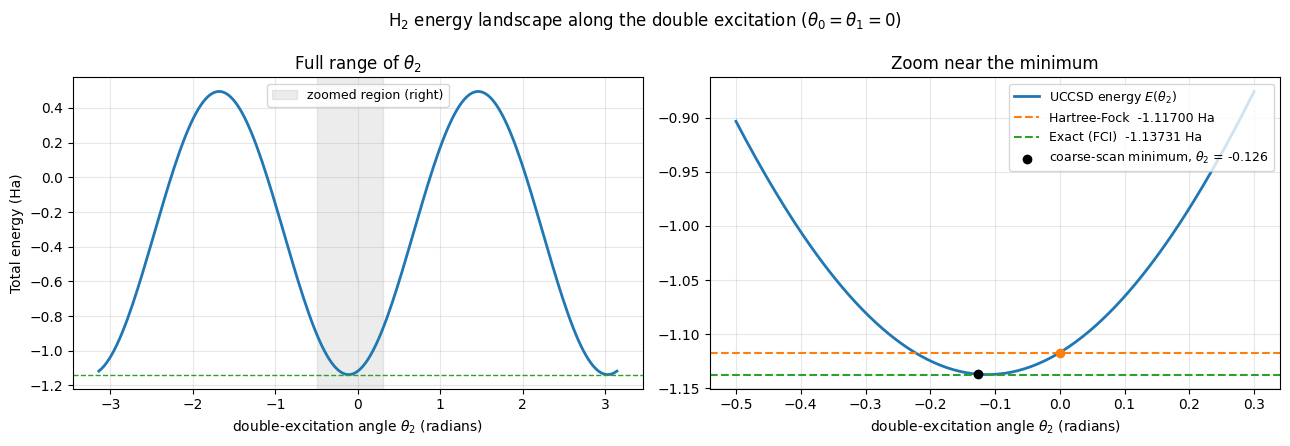

Best scanned energy : -1.136991 Ha at theta_2 = -0.1257 rad
Exact energy        : -1.137306 Ha
Gap (grid-limited)  : 0.3152 mHa


In [12]:
thetas = np.linspace(-np.pi, np.pi, 201)
landscape = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas]

i_min = int(np.argmin(landscape))
theta2_best, E_scan_best = thetas[i_min], landscape[i_min]

# Zoomed scan near the minimum, finer grid
thetas_zoom = np.linspace(-0.5, 0.3, 161)
landscape_zoom = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas_zoom]

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: the full period, showing the overall shape
ax_full.plot(thetas, landscape, color="tab:blue", lw=2)
ax_full.axhline(E_exact, color="tab:green", ls="--", lw=1)
ax_full.axvspan(-0.5, 0.3, color="grey", alpha=0.15, label="zoomed region (right)")
ax_full.set_title(r"Full range of $\theta_2$")
ax_full.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_full.set_ylabel("Total energy (Ha)")
ax_full.legend(loc="upper center", fontsize=9)
ax_full.grid(alpha=0.3)

# Right: zoom where HF and exact energies are visibly different (they differ by only ~20 mHa)
ax_zoom.plot(thetas_zoom, landscape_zoom, color="tab:blue", lw=2, label=r"UCCSD energy $E(\theta_2)$")
ax_zoom.axhline(hf_energy, color="tab:orange", ls="--", label=f"Hartree-Fock  {hf_energy:.5f} Ha")
ax_zoom.axhline(E_exact, color="tab:green", ls="--", label=f"Exact (FCI)  {E_exact:.5f} Ha")
ax_zoom.scatter([0.0], [hf_energy], color="tab:orange", zorder=5)
ax_zoom.scatter([theta2_best], [E_scan_best], color="black", zorder=5,
                label=rf"coarse-scan minimum, $\theta_2$ = {theta2_best:.3f}")
ax_zoom.set_title("Zoom near the minimum")
ax_zoom.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_zoom.legend(loc="upper right", fontsize=9)
ax_zoom.grid(alpha=0.3)

fig.suptitle(r"H$_2$ energy landscape along the double excitation ($\theta_0=\theta_1=0$)")
plt.tight_layout()
plt.show()

print(f"Best scanned energy : {E_scan_best:.6f} Ha at theta_2 = {theta2_best:.4f} rad")
print(f"Exact energy        : {E_exact:.6f} Ha")
print(f"Gap (grid-limited)  : {(E_scan_best - E_exact) * 1000:.4f} mHa")

**Reading the plot**
- **Left panel:** the energy is a smooth sinusoid that repeats every **π**. The double excitation
  rotates the state within a 2-dimensional space spanned by |0101⟩ (HF) and |1010⟩ (both electrons
  excited). Rotating by an extra π only flips the overall sign of the state, which has no physical
  effect, so the two minima are the *same* physical state.
- **Right panel (zoom):** at θ₂ = 0 the curve passes through the **HF energy** (orange dot), as
  expected. Moving to a small **negative** θ₂ lowers the energy down to the **exact line**. A small
  admixture of |1010⟩ is all H₂ needs.
- The curve **never goes below the exact line**, which is the variational principle in action.
- One parameter on a coarse grid already lands within a fraction of a mHa of the exact answer. That
  confirms our ansatz *can* represent the ground state, so the remaining job of VQE is optimisation.

### Phase 2 summary
| Item | Value |
|---|---|
| Ansatz | UCCSD = HF state + 2 single + 1 double excitation |
| Parameters | 3 |
| Hardware cost (transpiled) | 56 CNOTs; full counts and depth printed in section 8 |
| Validation | θ = 0 reproduces HF; matches the Qiskit Nature `UCCSD` class to < 1e-8 Ha |
| Landscape | The minimum along θ₂ reaches the exact energy, so the ansatz is expressive enough |

**Next (Phase 3):** run the real VQE loop. Qiskit's `Estimator` primitive will measure the energy,
and a classical optimizer will tune all 3 angles simultaneously, starting from θ = 0 (Hartree–Fock).

---
# Phase 3: Running VQE

## 11. Measuring energy with Qiskit's `Estimator` primitive

In Qiskit 2.x, the quantum half of VQE is handled by an **Estimator primitive**. You give it a *PUB*
(Primitive Unified Bloc), which is a tuple `(circuit, observable, parameter_values)`, and it returns
the expectation value $\langle\psi(\vec\theta)|\hat H|\psi(\vec\theta)\rangle$.

| Primitive | What it does | When we use it |
|---|---|---|
| `qiskit.primitives.StatevectorEstimator` | Exact, noise-free simulation (as if we had infinitely many shots) | **Phase 3**: check the algorithm itself is correct |
| `qiskit_aer.primitives.EstimatorV2` | Simulates a finite number of measurement shots | Phase 4: realistic shot noise |

**ISA circuits.** Real backends accept only the gates they physically support (their *Instruction
Set Architecture*). So we first **transpile** the ansatz for the Aer simulator backend, and
`apply_layout` re-labels the Hamiltonian's qubits to match. Every estimator in this notebook then
uses the same ISA circuit.

In [13]:
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

# Transpile the ansatz into gates the (Aer) backend supports -> "ISA" circuit
backend = AerSimulator()
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=7)
ansatz_isa = pass_manager.run(ansatz)
hamiltonian_isa = qubit_op.apply_layout(ansatz_isa.layout)   # keep qubit labels consistent

print(f"ISA circuit gate counts: {dict(ansatz_isa.count_ops())}")
print(f"ISA circuit parameters : {[p.name for p in ansatz_isa.parameters]}")


def make_cost_function(estimator):
    '''Build the function VQE minimises: theta -> total energy (Ha).

    Also returns a list that records every energy evaluation, so we can plot convergence.
    '''
    history = []

    def cost(theta):
        pub = (ansatz_isa, hamiltonian_isa, theta)          # (circuit, observable, parameter values)
        result = estimator.run([pub]).result()[0]           # one PUB in -> one result out
        energy = float(result.data.evs) + nuclear_repulsion # electronic energy + nuclear repulsion
        history.append(energy)
        return energy

    return cost, history


# Sanity check: at theta = 0 the estimator must return the Hartree-Fock energy
ideal_estimator = StatevectorEstimator()
cost_check, _ = make_cost_function(ideal_estimator)
E_check = cost_check(np.zeros(ansatz_isa.num_parameters))
print(f"\nEstimator at theta = 0 : {E_check:.10f} Ha (HF = {hf_energy:.10f} Ha)")
assert abs(E_check - hf_energy) < 1e-8

ISA circuit gate counts: {'cx': 56, 'u2': 25, 'rz': 12, 'h': 5, 'sxdg': 1}
ISA circuit parameters : ['θ[0]', 'θ[1]', 'θ[2]']

Estimator at theta = 0 : -1.1169989968 Ha (HF = -1.1169989968 Ha)


## 12. Choosing the classical optimizer and running VQE

The optimizer is the classical half of VQE. Each time it proposes angles $\vec\theta$, the estimator
answers with $E(\vec\theta)$, and the optimizer uses that answer to move "downhill".

We compare three standard optimizers from `scipy.optimize.minimize`, all starting from the **HF
point θ = (0, 0, 0)**:

| Optimizer | Type | How it decides where to go |
|---|---|---|
| **SLSQP** | gradient-based | Estimates the slope with finite differences (+ curvature updates). Very efficient when energies are exact. |
| **L-BFGS-B** | gradient-based | Quasi-Newton: builds an approximation of the curvature from past gradients |
| **COBYLA** | gradient-free | Fits a simple linear model to recent points. Needs more evaluations, but is more robust when energies are noisy (Phase 4). |

**What we measure:**
- the final error versus the exact energy;
- the **number of energy evaluations** (`nfev`). On real hardware every evaluation costs thousands of
  shots, so fewer evaluations means a cheaper experiment.

**Why start at θ = 0?** It is the HF state, which is already within ~20 mHa of the answer. A
physically motivated start avoids wandering around the landscape.

In [14]:
theta0 = np.zeros(ansatz_isa.num_parameters)   # start at the Hartree-Fock state
CHEM_ACC = 1.6e-3                                # chemical accuracy, in Ha

optimizer_settings = {
    "SLSQP":    {"maxiter": 200},
    "L-BFGS-B": {"maxiter": 200},
    "COBYLA":   {"maxiter": 500, "rhobeg": 0.1, "tol": 1e-8},   # rhobeg: initial step size (rad)
}

vqe_runs = {}
for name, options in optimizer_settings.items():
    cost, history = make_cost_function(StatevectorEstimator())
    result = minimize(cost, theta0, method=name, options=options)
    vqe_runs[name] = {"result": result, "history": history}

print(f"{'Optimizer':<10} {'E_VQE (Ha)':>15} {'Error (mHa)':>12} {'Evaluations':>12}   optimal theta (rad)")
for name, run in vqe_runs.items():
    r = run["result"]
    err_mHa = (r.fun - E_exact) * 1000
    print(f"{name:<10} {r.fun:>15.10f} {err_mHa:>12.2e} {len(run['history']):>12}   {np.round(r.x, 4)}")
    assert abs(r.fun - E_exact) < CHEM_ACC, f"{name} did not reach chemical accuracy"

print(f"\nExact (FCI) {E_exact:>15.10f}")
print("All three optimizers reach chemical accuracy.")

Optimizer       E_VQE (Ha)  Error (mHa)  Evaluations   optimal theta (rad)
SLSQP        -1.1373060357     5.65e-08           10   [-0.     -0.     -0.1118]
L-BFGS-B     -1.1373060358     1.11e-11           20   [ 0.     -0.     -0.1118]
COBYLA       -1.1373060358     1.02e-11           98   [-0.     -0.     -0.1118]

Exact (FCI)   -1.1373060358
All three optimizers reach chemical accuracy.


## 13. Convergence: how fast does each optimizer get there?

- **Left:** total energy versus the number of energy evaluations.
- **Right:** the *error* on a **log scale**, with the chemical-accuracy threshold as a red line. Every
  point below the red line is chemically accurate.

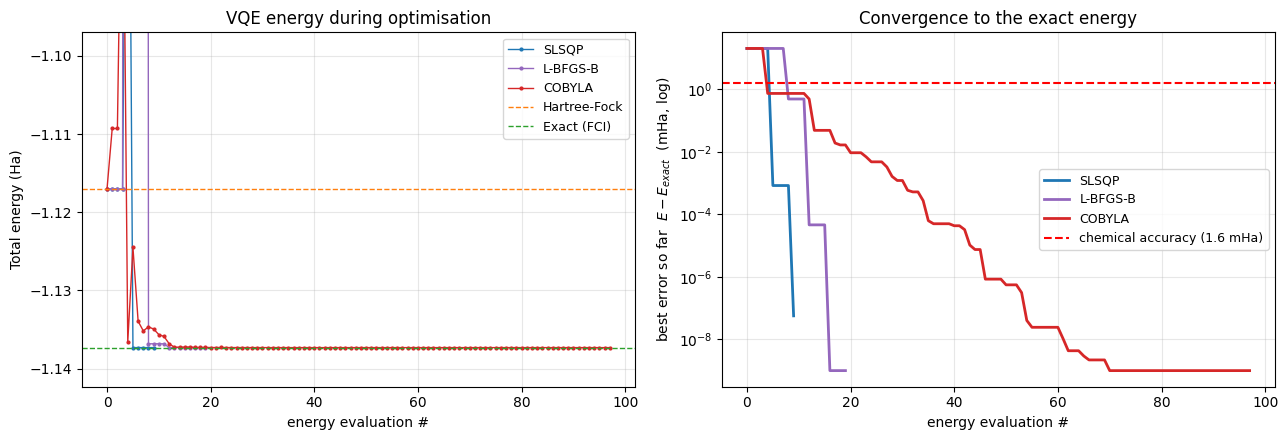

In [15]:
fig, (ax_e, ax_err) = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"SLSQP": "tab:blue", "L-BFGS-B": "tab:purple", "COBYLA": "tab:red"}

for name, run in vqe_runs.items():
    h = np.array(run["history"])
    ax_e.plot(h, color=colors[name], marker=".", ms=4, lw=1, label=name)
    # running best (lowest energy found so far); floor at 1e-12 so log scale works if error hits ~0
    best_so_far = np.minimum.accumulate(h)
    ax_err.semilogy(np.maximum(best_so_far - E_exact, 1e-12) * 1000, color=colors[name], lw=2, label=name)

ax_e.axhline(hf_energy, color="tab:orange", ls="--", lw=1, label="Hartree-Fock")
ax_e.axhline(E_exact, color="tab:green", ls="--", lw=1, label="Exact (FCI)")
ax_e.set_xlabel("energy evaluation #")
ax_e.set_ylabel("Total energy (Ha)")
ax_e.set_title("VQE energy during optimisation")
ax_e.set_ylim(E_exact - 0.005, hf_energy + 0.02)
ax_e.legend(fontsize=9)
ax_e.grid(alpha=0.3)

ax_err.axhline(CHEM_ACC * 1000, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax_err.set_xlabel("energy evaluation #")
ax_err.set_ylabel(r"best error so far  $E - E_{exact}$  (mHa, log)")
ax_err.set_title("Convergence to the exact energy")
ax_err.legend(fontsize=9)
ax_err.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

**Reading the plot**
- **SLSQP and L-BFGS-B** converge in a handful of iterations. With exact energies, finite-difference
  gradients are reliable, and for H₂ the landscape near HF is a smooth, almost quadratic bowl.
- **COBYLA** uses no gradients, so it explores more and needs several times as many evaluations,
  but it still reaches the same answer.
- No evaluation ever goes **below** the exact energy, as the variational principle requires.
- *Plot details:* a few early points shoot above the left plot's range. These are large trial steps
  and finite-difference probes, which the optimizer then rejects. On the right, the curves flatten
  near 10⁻⁹ mHa. That is the floor we set for the log scale at the limit of floating-point precision,
  not an optimizer limitation.

## 14. What did VQE find? Interpreting the optimal state

A number that matches is good, but we should also check that VQE found the **right quantum state**:

1. **Optimal angles:** we expect θ₀ ≈ θ₁ ≈ 0 (singles unused, Brillouin's theorem) and a small negative θ₂.
2. **Composition:** which basis states make up $|\psi(\vec\theta^*)\rangle$, and with what probability?
3. **Fidelity** $F = |\langle \psi_{\text{exact}} | \psi_{\text{VQE}} \rangle|^2$ with the exact ground
   state from diagonalisation. $F = 1$ means the states are identical.

In [16]:
best_name = min(vqe_runs, key=lambda n: vqe_runs[n]["result"].fun)
theta_opt = vqe_runs[best_name]["result"].x
E_vqe = vqe_runs[best_name]["result"].fun

print(f"Best run: {best_name}")
for k, label in enumerate(gate_labels):
    print(f"  theta[{k}] ({label:<8}) = {theta_opt[k]:+.5f} rad")

# State prepared by VQE (logical ansatz, decomposed to elementary gates)
psi_vqe = Statevector(ansatz.assign_parameters(theta_opt).decompose())
print("\nComposition of the VQE state (bitstring = q3 q2 q1 q0):")
for bitstring, p in sorted(psi_vqe.probabilities_dict().items(), key=lambda kv: -kv[1]):
    if p > 1e-6:
        print(f"  |{bitstring}>  probability {p:.5f}")

# Exact ground state: eigenvector of the 16x16 Hamiltonian matrix with the lowest eigenvalue
evals, evecs = np.linalg.eigh(qubit_op.to_matrix())
psi_exact = Statevector(evecs[:, 0])
fidelity = abs(np.vdot(psi_exact.data, psi_vqe.data)) ** 2
print(f"\nFidelity |<psi_exact|psi_VQE>|^2 = {fidelity:.10f}")
assert fidelity > 0.9999

Best run: COBYLA
  theta[0] (single α) = -0.00000 rad
  theta[1] (single β) = -0.00000 rad
  theta[2] (double  ) = -0.11177 rad

Composition of the VQE state (bitstring = q3 q2 q1 q0):
  |0101>  probability 0.98756
  |1010>  probability 0.01244

Fidelity |<psi_exact|psi_VQE>|^2 = 1.0000000000


**Physical interpretation**
- θ₀ and θ₁ come out as **zero**: the optimizer independently "discovered" Brillouin's theorem.
- The ground state is about **98.7% |0101⟩** (both electrons in the bonding orbital σg) and **1.3%
  |1010⟩** (both in the antibonding orbital σu*).
- That small 1.3% admixture is the *electron correlation*. By sometimes occupying the antibonding
  orbital together, the electrons avoid each other a little and lower the energy by ~20 mHa.
- A fidelity of essentially 1 means VQE found the *exact* ground-state wavefunction, not just a state
  that happens to have the right energy.

## 15. Cross-check with Qiskit's built-in `VQE` class

Our VQE loop above is written by hand so that every step is visible. As an independent check, we run
the same ansatz and Hamiltonian through `qiskit_algorithms.VQE`, the library implementation, and
confirm it agrees.

In [17]:
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP as QiskitSLSQP

library_vqe = VQE(StatevectorEstimator(), ansatz_isa, QiskitSLSQP(maxiter=200), initial_point=theta0)
library_result = library_vqe.compute_minimum_eigenvalue(hamiltonian_isa)
E_library_vqe = library_result.eigenvalue.real + nuclear_repulsion   # library returns electronic energy only

print(f"qiskit_algorithms.VQE : {E_library_vqe:.10f} Ha  ({library_result.cost_function_evals} evaluations)")
print(f"Our VQE loop ({best_name}) : {E_vqe:.10f} Ha")
print(f"Exact (FCI)           : {E_exact:.10f} Ha")
assert abs(E_library_vqe - E_vqe) < 1e-6
print("\nThe library VQE agrees with our implementation.")

qiskit_algorithms.VQE : -1.1373060357 Ha  (10 evaluations)
Our VQE loop (COBYLA) : -1.1373060358 Ha
Exact (FCI)           : -1.1373060358 Ha

The library VQE agrees with our implementation.


In [18]:
error_mHa = (E_vqe - E_exact) * 1000
recovered = (hf_energy - E_vqe) / (hf_energy - E_exact) * 100

print("=" * 58)
print(f"{'H2 ground-state energy, STO-3G, R = 0.735 A':^58}")
print("=" * 58)
print(f"Hartree-Fock (mean field)      : {hf_energy:.8f} Ha")
vqe_label = f"VQE (UCCSD, {best_name})"
print(f"{vqe_label:<31}: {E_vqe:.8f} Ha")
print(f"Exact (FCI / diagonalisation)  : {E_exact:.8f} Ha")
print("-" * 58)
print(f"VQE error vs exact             : {error_mHa:.2e} mHa")
print(f"Chemical accuracy (1.6 mHa)?   : {'YES' if abs(error_mHa) < 1.6 else 'NO'}")
print(f"Correlation energy recovered   : {recovered:.4f} %")
print(f"State fidelity with exact      : {fidelity:.8f}")
print("=" * 58)

       H2 ground-state energy, STO-3G, R = 0.735 A        
Hartree-Fock (mean field)      : -1.11699900 Ha
VQE (UCCSD, COBYLA)            : -1.13730604 Ha
Exact (FCI / diagonalisation)  : -1.13730604 Ha
----------------------------------------------------------
VQE error vs exact             : 1.02e-11 mHa
Chemical accuracy (1.6 mHa)?   : YES
Correlation energy recovered   : 100.0000 %
State fidelity with exact      : 1.00000000


### Phase 3 summary
- On an ideal (noise-free) simulator, **VQE with the UCCSD ansatz reproduces the exact ground-state
  energy of H₂**. The error is many orders of magnitude below chemical accuracy, and essentially 100% of
  the correlation energy is recovered.
- Two independent checks agree: **the state fidelity ≈ 1** and the **library `VQE`** result.
- SLSQP is the most efficient optimizer here (fewest evaluations); COBYLA is slower but gradient-free.

**Next (Phase 4):** make it realistic. Real quantum computers estimate energies from a **finite number of
measurement shots**, which adds statistical noise. We will study how shot noise affects accuracy and
which optimizer copes best. We will also scan the bond length to draw H₂'s **potential-energy curve**.

---
# Phase 4: Realistic conditions and chemistry insight

## 16. Shot noise: what a real quantum computer actually measures

So far the estimator returned *exact* expectation values. A real quantum computer cannot do that:
- Measuring a qubit gives a **random 0 or 1**, so every energy is an *average over repeated runs*
  called **shots**.
- Each Pauli term needs its own measurement basis. Terms that **qubit-wise commute** can be measured
  together, so the Hamiltonian is split into **measurement groups**.
- Averaging $N$ shots leaves a statistical error that shrinks like $1/\sqrt{N}$. To get **10× more
  precise** you need **100× more shots**.

**How we simulate this.** We use `BackendEstimatorV2` running on the `AerSimulator`. It really
**samples bitstrings**, shot by shot, in each measurement basis, exactly as hardware would.
- `precision` sets shots per group: shots = $\lceil 1/\text{precision}^2 \rceil$.
- We give the simulator a **new seed for every call**. The notebook stays reproducible, but every
  measurement still has independent noise.

> **Why not `qiskit_aer.primitives.EstimatorV2`?** We read its source code. It computes the exact value
> and adds Gaussian noise $\mathcal N(E, \text{precision})$, which is an *approximation* of shot noise.
> With a fixed seed it also adds **the same noise** on every call. We prefer real sampling.

*Still idealised:* the gates themselves are perfect (no device noise). We isolate one error source at a time.

In [19]:
import itertools
from qiskit.primitives import BackendEstimatorV2

shot_backend = AerSimulator()                       # samples measurement outcomes shot by shot
shot_estimator = BackendEstimatorV2(backend=shot_backend)
seed_counter = itertools.count(start=2026)          # new seed per call -> independent but reproducible noise

groups = hamiltonian_isa.group_commuting(qubit_wise=True)
print(f"Hamiltonian: {len(hamiltonian_isa)} Pauli terms -> {len(groups)} measurement groups:")
for g in groups:
    print("   ", g.paulis.to_labels())


def noisy_energy(theta, shots):
    '''Total energy estimated from `shots` measurements per group (statistical noise included).'''
    shot_backend.set_options(seed_simulator=next(seed_counter))
    result = shot_estimator.run([(ansatz_isa, hamiltonian_isa, theta)], precision=1 / np.sqrt(shots)).result()[0]
    return float(result.data.evs) + nuclear_repulsion


def exact_energy(theta):
    '''Noise-free energy of the same circuit, which we use to judge the *true* quality of a theta.'''
    return float(StatevectorEstimator().run([(ansatz_isa, hamiltonian_isa, theta)]).result()[0].data.evs) + nuclear_repulsion


# Confirm the precision -> shots conversion
meta = shot_estimator.run([(ansatz_isa, hamiltonian_isa, theta_opt)], precision=1 / np.sqrt(10_000)).result()[0].metadata
print(f"\nprecision 1/sqrt(10000) -> shots per group used by the estimator: {meta['shots']}")

Hamiltonian: 15 Pauli terms -> 5 measurement groups:
    ['YYYY', 'IIII']
    ['XXYY']
    ['YYXX']
    ['XXXX']
    ['IIIZ', 'IIZI', 'IIZZ', 'IZII', 'IZIZ', 'ZIII', 'ZIIZ', 'IZZI', 'ZIZI', 'ZZII']

precision 1/sqrt(10000) -> shots per group used by the estimator: 10000


**Experiment:** keep the angles fixed at the optimal $\vec\theta^*$ from Phase 3 and repeat the
energy measurement **30 times** at each shot count. The spread of those 30 values is the shot noise.

shots/group  mean error (mHa)  std dev (mHa)  within 1.6 mHa


        100            -4.401         15.948             10%


      1,000            -0.115          7.106             13%


     10,000            -0.235          1.791             60%


    100,000            +0.095          0.654            100%


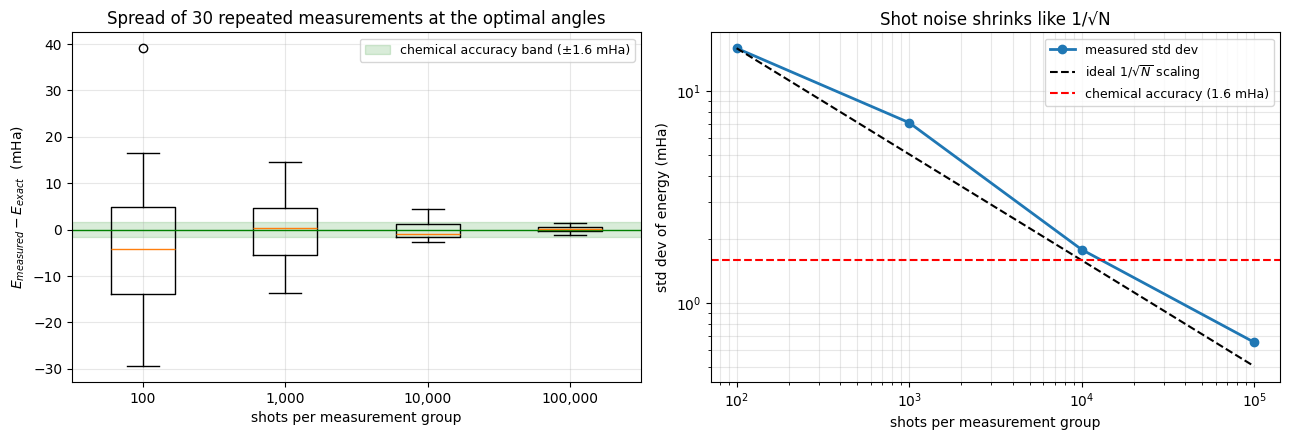

In [20]:
shot_levels = [100, 1_000, 10_000, 100_000]
N_REPEATS = 30

noise_stats = {}
print(f"{'shots/group':>11} {'mean error (mHa)':>17} {'std dev (mHa)':>14} {'within 1.6 mHa':>15}")
for shots in shot_levels:
    samples = np.array([noisy_energy(theta_opt, shots) for _ in range(N_REPEATS)])
    errors_mHa = (samples - E_exact) * 1000
    noise_stats[shots] = errors_mHa
    frac_ok = np.mean(np.abs(errors_mHa) < 1.6) * 100
    print(f"{shots:>11,} {errors_mHa.mean():>+17.3f} {errors_mHa.std(ddof=1):>14.3f} {frac_ok:>14.0f}%")

fig, (ax_box, ax_std) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_box.boxplot([noise_stats[s] for s in shot_levels], tick_labels=[f"{s:,}" for s in shot_levels])
ax_box.axhspan(-1.6, 1.6, color="green", alpha=0.15, label="chemical accuracy band (±1.6 mHa)")
ax_box.axhline(0, color="green", lw=1)
ax_box.set_xlabel("shots per measurement group")
ax_box.set_ylabel(r"$E_{measured} - E_{exact}$  (mHa)")
ax_box.set_title(f"Spread of {N_REPEATS} repeated measurements at the optimal angles")
ax_box.legend(fontsize=9, loc="upper right")
ax_box.grid(alpha=0.3)

stds = np.array([noise_stats[s].std(ddof=1) for s in shot_levels])
ax_std.loglog(shot_levels, stds, "o-", color="tab:blue", lw=2, label="measured std dev")
ref = stds[0] * np.sqrt(shot_levels[0] / np.array(shot_levels))   # ideal 1/sqrt(N) through first point
ax_std.loglog(shot_levels, ref, "k--", label=r"ideal $1/\sqrt{N}$ scaling")
ax_std.axhline(1.6, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax_std.set_xlabel("shots per measurement group")
ax_std.set_ylabel("std dev of energy (mHa)")
ax_std.set_title("Shot noise shrinks like 1/√N")
ax_std.legend(fontsize=9)
ax_std.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

**Reading the plots**
- The noise follows the **1/√N law** closely, a signature of independent random sampling.
- To keep a *single* energy measurement reliably inside chemical accuracy, we need on the order of
  **10⁴–10⁵ shots per group**. Even the tiny H₂ problem demands a large shot budget, which is one of
  VQE's main practical costs.
- Individual measurements can land **below** the exact energy. That does **not** break the variational
  principle: noise can push an *estimate* below $E_0$, but the *true* energy of the state cannot go below it.

## 17. VQE under shot noise: which optimizer survives?

Now we run the **full VQE loop** with noisy energies (10,000 shots per group per evaluation), starting
from HF. We compare:

| Optimizer | Expectation under noise |
|---|---|
| **SLSQP** | Gradients come from *differences* of nearby noisy energies. With a step of ~10⁻⁸ rad, the true difference is tiny and the noise is huge, so the gradient becomes garbage. **Expected to fail.** |
| **COBYLA** | Gradient-free, so it tolerates noise. It may stop early because noise hides small improvements. |
| **SPSA** (*Simultaneous Perturbation Stochastic Approximation*) | Designed for noisy objectives. Each step perturbs **all** angles at once by a random ±δ and uses just **2 evaluations**; step sizes shrink over time to average out noise. The standard choice on real hardware. |

**Two numbers per run:**
- **Reported energy:** the optimizer's own (noisy) best value. This is what an experimenter sees.
- **True energy:** we re-evaluate the final angles *exactly*. This tells us how good the state found really is.

Each optimizer runs **3 times with different seeds**, so we are not judging from a single lucky or unlucky run.

In [21]:
from qiskit_algorithms.optimizers import SPSA
from qiskit_algorithms.utils import algorithm_globals

NOISY_SHOTS = 10_000
N_TRIALS = 3


def run_noisy_vqe(optimizer_name, trial):
    '''One VQE run from HF with shot-noisy energies; returns reported/true energy and #evaluations.'''
    n_evals = [0]

    def cost(theta):
        n_evals[0] += 1
        return noisy_energy(theta, NOISY_SHOTS)

    if optimizer_name == "SPSA":
        algorithm_globals.random_seed = 100 + trial          # SPSA draws random perturbation directions
        spsa = SPSA(maxiter=100, learning_rate=0.05, perturbation=0.05)
        res = spsa.minimize(cost, theta0)
    elif optimizer_name == "COBYLA":
        res = minimize(cost, theta0, method="COBYLA", options={"maxiter": 200, "rhobeg": 0.1})
    else:  # SLSQP
        res = minimize(cost, theta0, method="SLSQP", options={"maxiter": 100})
    return {"reported": res.fun, "true": exact_energy(res.x), "evals": n_evals[0], "theta": res.x}


noisy_results = {name: [run_noisy_vqe(name, t) for t in range(N_TRIALS)] for name in ["SLSQP", "COBYLA", "SPSA"]}

print(f"{NOISY_SHOTS:,} shots per group per evaluation, {len(groups)} groups, starting from HF\n")
print(f"{'Optimizer':<8} {'trial':>5} {'reported err (mHa)':>19} {'TRUE err (mHa)':>15} {'evals':>6} {'total shots':>12}")
for name, runs in noisy_results.items():
    for t, r in enumerate(runs):
        total_shots = r["evals"] * len(groups) * NOISY_SHOTS
        print(f"{name:<8} {t:>5} {(r['reported'] - E_exact) * 1000:>+19.3f} "
              f"{(r['true'] - E_exact) * 1000:>15.3f} {r['evals']:>6} {total_shots:>12.1e}")
    print()

10,000 shots per group per evaluation, 5 groups, starting from HF

Optimizer trial  reported err (mHa)  TRUE err (mHa)  evals  total shots
SLSQP        0            +743.548         742.358    239      1.2e+07
SLSQP        1            +403.970         401.102    211      1.1e+07
SLSQP        2            +801.986         801.539    211      1.1e+07

COBYLA       0              +9.991           3.144     29      1.4e+06
COBYLA       1              +1.261           0.972     27      1.4e+06
COBYLA       2              -0.161           0.854     28      1.4e+06

SPSA         0              +0.412           0.019    201      1.0e+07
SPSA         1              +2.946           0.010    201      1.0e+07
SPSA         2              -2.052           0.092    201      1.0e+07



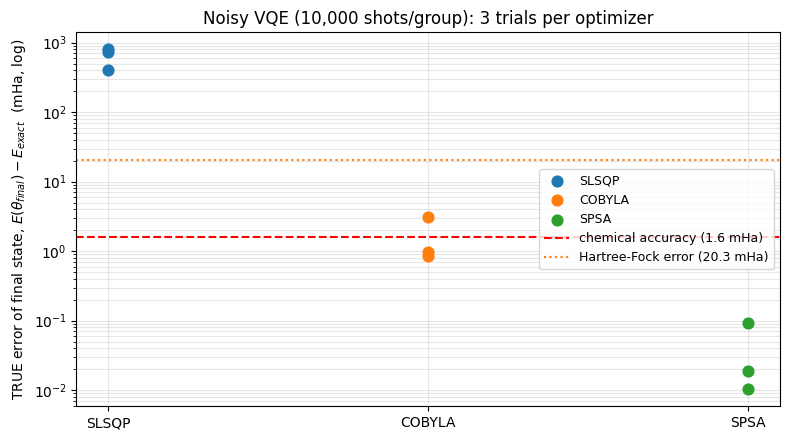

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(noisy_results)
for i, name in enumerate(names):
    true_err = [(r["true"] - E_exact) * 1000 for r in noisy_results[name]]
    ax.scatter([i] * len(true_err), true_err, s=60, zorder=3, label=f"{name}")
ax.axhline(1.6, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax.axhline(hf_energy * 1000 - E_exact * 1000, color="tab:orange", ls=":", label="Hartree-Fock error (20.3 mHa)")
ax.set_yscale("log")
ax.set_xticks(range(len(names)), names)
ax.set_ylabel(r"TRUE error of final state, $E(\theta_{final}) - E_{exact}$  (mHa, log)")
ax.set_title(f"Noisy VQE ({NOISY_SHOTS:,} shots/group): {N_TRIALS} trials per optimizer")
ax.legend(fontsize=9, loc="center right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

**Reading the results**
- **SLSQP fails dramatically.** Its finite-difference gradients are dominated by noise, the angles
  run off to huge values, and the final state is *worse than Hartree–Fock*. This is the clearest
  lesson of the experiment: **an optimizer that is the best on a noise-free simulator can be the worst
  on real hardware.**
- **COBYLA** is noise-tolerant but tends to **stop early**: once noise hides further improvement it
  declares convergence. It lands near (and sometimes outside) chemical accuracy.
- **SPSA** reliably reaches chemical accuracy. Its random simultaneous perturbations and shrinking
  steps average the noise out over many cheap iterations. That reliability costs more evaluations
  and therefore more shots.
- **Reported energies are not trustworthy on their own.** Some optimizers report values *below* the
  exact energy (a "winner's curse": the minimum of many noisy values is biased low). On real hardware we
  would re-measure the final angles with many more shots to get an honest estimate.

## 18. The potential-energy curve: breaking the H₂ bond

The bond length 0.735 Å was an input. A real test of a quantum-chemistry method is whether it describes
the molecule at **every** geometry, including when the bond is **stretched and breaks**.

For each bond length $R$ we:
1. rebuild the molecule with PySCF and map its new Hamiltonian with Jordan–Wigner;
2. compute HF and the exact **FCI** energy (PySCF);
3. run (ideal) VQE with SLSQP.

**Two useful details:**
- **The ansatz does not change with geometry.** The excitation operators depend only on how many
  orbitals and electrons there are, not on the bond length. Only the Hamiltonian changes, so
  `ansatz_isa` is reused.
- **Warm start:** each VQE starts from the optimal angles of the previous bond length. Neighbouring
  geometries have similar ground states, so this saves evaluations. This is standard practice in scans.

**Physics to watch:** as the bond stretches, the two electrons should end up one on each H atom. HF
forces both electrons into the *same* σg orbital, so it wrongly keeps ~50% "both electrons on one atom"
(ionic H⁺H⁻) character. HF therefore gets **worse and worse** at long bond lengths (*static
correlation*). UCCSD can fix this by mixing |0101⟩ and |1010⟩ equally.

In [23]:
bond_lengths = np.round(np.concatenate([np.arange(0.30, 1.00, 0.05), np.arange(1.0, 3.01, 0.20)]), 3)

pes = {"R": [], "hf": [], "fci": [], "vqe": [], "theta2": []}
theta_warm = np.zeros(ansatz_isa.num_parameters)

for R in bond_lengths:
    # 1) molecule + qubit Hamiltonian at this geometry (same settings as Section 1)
    prob_R = PySCFDriver(atom=f"H 0 0 0; H 0 0 {R}", basis="sto3g", charge=0, spin=0,
                         unit=DistanceUnit.ANGSTROM).run()
    H_R = mapper.map(prob_R.hamiltonian.second_q_op()).apply_layout(ansatz_isa.layout)
    E_nuc_R = prob_R.hamiltonian.nuclear_repulsion_energy

    # 2) exact reference: PySCF FCI (fixed 2 electrons, singlet)
    mf_R = scf.RHF(gto.M(atom=f"H 0 0 0; H 0 0 {R}", basis="sto-3g", unit="Angstrom")).run(verbose=0)
    E_fci_R = fci.FCI(mf_R).kernel()[0]

    # 3) ideal VQE, warm-started from the previous geometry's optimum
    def cost_R(theta):
        return float(StatevectorEstimator().run([(ansatz_isa, H_R, theta)]).result()[0].data.evs) + E_nuc_R
    res_R = minimize(cost_R, theta_warm, method="SLSQP", options={"maxiter": 200, "ftol": 1e-10})
    theta_warm = res_R.x

    pes["R"].append(R); pes["hf"].append(prob_R.reference_energy); pes["fci"].append(E_fci_R)
    pes["vqe"].append(res_R.fun); pes["theta2"].append(res_R.x[2])

pes = {k: np.array(v) for k, v in pes.items()}
vqe_err = np.abs(pes["vqe"] - pes["fci"]) * 1000
i_eq = int(np.argmin(pes["vqe"]))
print(f"Scanned {len(bond_lengths)} bond lengths from {bond_lengths[0]} to {bond_lengths[-1]} A")
print(f"Max |VQE - FCI| over the whole curve : {vqe_err.max():.2e} mHa")
print(f"Max |HF  - FCI| over the whole curve : {np.max(pes['hf'] - pes['fci']) * 1000:.1f} mHa (at R = {pes['R'][np.argmax(pes['hf'] - pes['fci'])]} A)")
print(f"VQE equilibrium bond length (grid)   : {pes['R'][i_eq]} A  (experiment ~0.741 A)")
assert vqe_err.max() < 1.6, "VQE lost chemical accuracy somewhere on the curve"

# Bond dissociation energy: E(far apart) - E(equilibrium), in the minimal basis
D_e = (pes["vqe"][-1] - pes["vqe"][i_eq]) * 27.2114
print(f"Bond energy estimate E(3.0 A) - E(eq): {D_e:.2f} eV  (STO-3G; experiment ~4.75 eV)")

Scanned 25 bond lengths from 0.3 to 3.0 A
Max |VQE - FCI| over the whole curve : 3.34e-08 mHa
Max |HF  - FCI| over the whole curve : 277.6 mHa (at R = 3.0 A)
VQE equilibrium bond length (grid)   : 0.75 A  (experiment ~0.741 A)
Bond energy estimate E(3.0 A) - E(eq): 5.54 eV  (STO-3G; experiment ~4.75 eV)


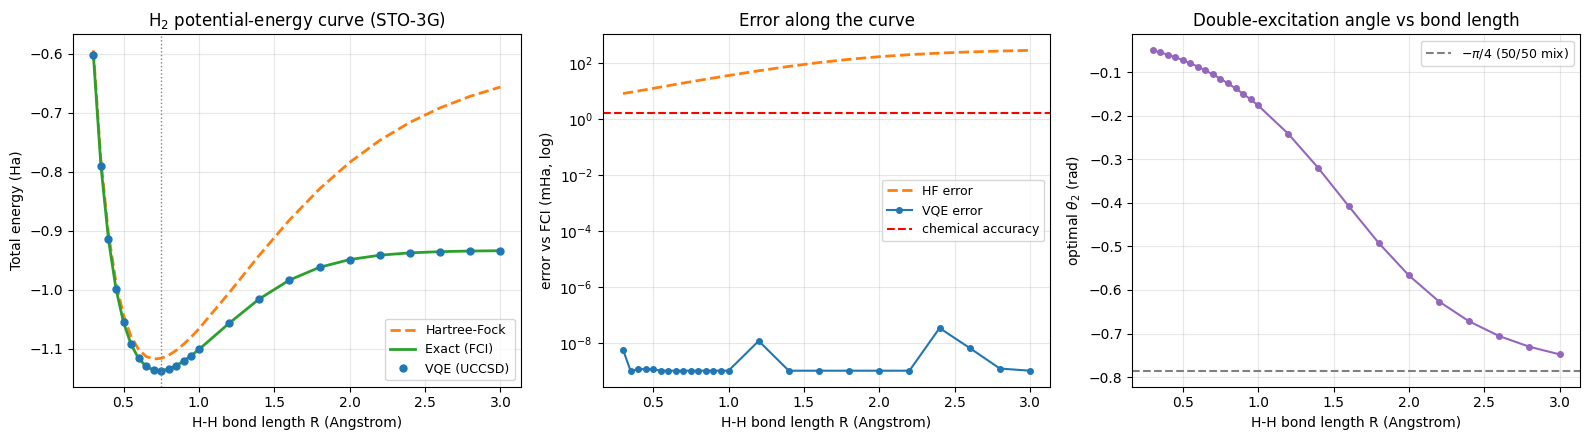

In [24]:
fig, (ax_pes, ax_err, ax_th) = plt.subplots(1, 3, figsize=(16, 4.5))

ax_pes.plot(pes["R"], pes["hf"], "--", color="tab:orange", lw=2, label="Hartree-Fock")
ax_pes.plot(pes["R"], pes["fci"], "-", color="tab:green", lw=2, label="Exact (FCI)")
ax_pes.plot(pes["R"], pes["vqe"], "o", color="tab:blue", ms=5, label="VQE (UCCSD)")
ax_pes.axvline(pes["R"][i_eq], color="grey", ls=":", lw=1)
ax_pes.set_xlabel("H-H bond length R (Angstrom)")
ax_pes.set_ylabel("Total energy (Ha)")
ax_pes.set_title(r"H$_2$ potential-energy curve (STO-3G)")
ax_pes.legend(fontsize=9)
ax_pes.grid(alpha=0.3)

ax_err.semilogy(pes["R"], (pes["hf"] - pes["fci"]) * 1000, "--", color="tab:orange", lw=2, label="HF error")
ax_err.semilogy(pes["R"], np.maximum(vqe_err, 1e-9), "o-", color="tab:blue", ms=4, label="VQE error")
ax_err.axhline(1.6, color="red", ls="--", label="chemical accuracy")
ax_err.set_xlabel("H-H bond length R (Angstrom)")
ax_err.set_ylabel("error vs FCI (mHa, log)")
ax_err.set_title("Error along the curve")
ax_err.legend(fontsize=9)
ax_err.grid(alpha=0.3, which="both")

ax_th.plot(pes["R"], pes["theta2"], "o-", color="tab:purple", ms=4)
ax_th.axhline(-np.pi / 4, color="grey", ls="--", label=r"$-\pi/4$ (50/50 mix)")
ax_th.set_xlabel("H-H bond length R (Angstrom)")
ax_th.set_ylabel(r"optimal $\theta_2$ (rad)")
ax_th.set_title("Double-excitation angle vs bond length")
ax_th.legend(fontsize=9)
ax_th.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Reading the plots**
- **Left:** VQE (dots) lies on the exact curve everywhere. The minimum of the curve gives the
  equilibrium bond length, close to the experimental 0.741 Å. HF is fine near equilibrium but rises far
  too high when the bond is stretched: it predicts the wrong energy for two separate H atoms.
- **Middle:** the HF error grows from ~8 mHa to **~280 mHa** as the bond breaks, while the VQE error
  stays many orders of magnitude below chemical accuracy at every geometry. The VQE values near 10⁻⁹ mHa
  are the optimizer's numerical tolerance, effectively zero.
- **Right:** the optimal θ₂ explains *why*. Near equilibrium a small rotation (a ~1% admixture of |1010⟩)
  is enough. As the bond stretches, θ₂ heads towards **−π/4**, an **equal mix** of |0101⟩ and |1010⟩.
  That combination cancels the unphysical ionic H⁺H⁻ part and leaves one electron on each atom.
  A single Slater determinant (HF) can never do this. VQE learns it automatically.
- **Bond energy:** our estimate is in the right ballpark of experiment but not exact. That is a
  limitation of the tiny **STO-3G basis**, not of VQE: VQE reproduces FCI *within the basis we gave it*.

---
# Conclusions

## What we did
1. Built the **H₂ molecular Hamiltonian** with PySCF and mapped it to a **4-qubit, 15-term** Pauli
   Hamiltonian with the Jordan–Wigner transformation.
2. Established an **exact reference**, cross-checked three independent ways.
3. Built and validated a **3-parameter UCCSD ansatz** without deprecated components.
4. Ran **VQE** with several optimizers and recovered **100% of the correlation energy** with state
   fidelity ≈ 1.
5. Studied **shot noise** (1/√N scaling) and **optimizer robustness**, then reproduced the full
   **potential-energy curve**, including bond breaking where Hartree–Fock fails.

## Key insights
- The ansatz must be able to *represent* the answer. UCCSD captures exactly the physics H₂ needs:
  the double excitation.
- **Noise changes which optimizer is best.** SLSQP wins without noise and fails with it; SPSA is the
  robust choice for hardware.
- **Verification is essential.** Every quantum result in this notebook is checked against a classical answer.

## Limitations (honest assessment)
- **Minimal basis (STO-3G).** The *exact* answer in this basis still differs from experiment.
  Larger basis sets need more qubits.
- **No hardware noise model.** We simulated shot noise only; real devices also have gate and readout
  errors. With 56 CNOTs, the circuit would need error mitigation on today's hardware.
- **H₂ is classically easy.** Exact diagonalisation is trivial at 4 qubits. The value here is in a
  verified, well-understood pipeline, not quantum advantage.

## Possible extensions
- Qubit reduction (Parity mapping with 2-qubit reduction / symmetry tapering: 4 → 1–2 qubits)
- Device noise models (`qiskit-ibm-runtime` fake backends) plus error mitigation (e.g. zero-noise extrapolation)
- Larger molecules (LiH, BeH₂) with active-space reduction; adaptive ansätze (ADAPT-VQE)

In [25]:
print("=" * 66)
print(f"{'FINAL RESULTS: H2 / STO-3G / Jordan-Wigner / UCCSD':^66}")
print("=" * 66)
print(f"Qubits / Pauli terms / ansatz parameters : {qubit_op.num_qubits} / {len(qubit_op)} / {ansatz.num_parameters}")
print(f"Exact ground-state energy (R = {BOND_LENGTH} A)  : {E_exact:.8f} Ha")
print(f"Ideal VQE energy                         : {E_vqe:.8f} Ha  (error {abs(E_vqe - E_exact) * 1000:.1e} mHa)")
spsa_true = [(r["true"] - E_exact) * 1000 for r in noisy_results["SPSA"]]
print(f"Noisy VQE, SPSA (true error)             : mean {np.mean(spsa_true):.3f} mHa ({N_TRIALS} trials, {NOISY_SHOTS:,} shots/group)")
print(f"Potential-energy curve, max VQE error    : {vqe_err.max():.1e} mHa over {len(bond_lengths)} geometries")
print(f"Chemical accuracy (1.6 mHa) achieved     : ideal YES | noisy SPSA "
      f"{'YES' if max(spsa_true) < 1.6 else 'NO'} | full curve {'YES' if vqe_err.max() < 1.6 else 'NO'}")
print("=" * 66)

        FINAL RESULTS: H2 / STO-3G / Jordan-Wigner / UCCSD        
Qubits / Pauli terms / ansatz parameters : 4 / 15 / 3
Exact ground-state energy (R = 0.735 A)  : -1.13730604 Ha
Ideal VQE energy                         : -1.13730604 Ha  (error 1.0e-11 mHa)
Noisy VQE, SPSA (true error)             : mean 0.041 mHa (3 trials, 10,000 shots/group)
Potential-energy curve, max VQE error    : 3.3e-08 mHa over 25 geometries
Chemical accuracy (1.6 mHa) achieved     : ideal YES | noisy SPSA YES | full curve YES
